# 04b: Funções de perda × seeds (task 20)

**Pergunta:** com o mesmo STGCN, o mesmo otimizador e o mesmo orçamento de passos, trocar a função de perda do treino melhora o erro na escala real da taxa?

Comparamos três perdas. Em todas, o modelo sai em `log1p` e a previsão volta à taxa com `expm1`:

| Perda | O que mede no treino | Ideia |
| --- | --- | --- |
| `mse` | erro quadrático em `log1p` | a perda usada até aqui |
| `huber` (δ = 1) | quadrática nos erros pequenos, linear nos grandes, em `log1p` | erros grandes (surtos) pesam menos |
| `tweedie` (p = 1,5) | perda Tweedie sobre `taxa + 1` | feita para dados com muitos zeros e cauda longa; estima a **média** da taxa |

Configuração comum: STGCN com grafo geo, AdamW (η = 1e-2), warmup + cosseno, 920 passos, lote 32, seeds 0, 1 e 2. A melhor época é escolhida pela validação **na própria perda** de cada treino. A comparação é sempre pelo MAE e RMSE na taxa bruta, nunca pela perda.

Este notebook só lê os resultados. Para regerar (cerca de 9 min na CPU):

```
python -m dengue.experimento configs/perdas/mse.yaml --resultados results/perdas
python -m dengue.experimento configs/perdas/huber.yaml --resultados results/perdas
python -m dengue.experimento configs/perdas/tweedie.yaml --resultados results/perdas
```

Tudo é medido na **validação (2013 a 2015)**. O teste não é usado aqui.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dengue import dados, experimento

RES = dados.RAIZ / 'results'
exp = pd.read_csv(RES / 'perdas' / 'experimentos.csv')
assert not exp['divergiu'].any()

H = np.arange(1, dados.H + 1)
colunas = (['mae', 'rmse', 'mae_surto', 'mae_calmaria', 'vies_surto', 'vies_calmaria']
           + [f'mae_h{h}' for h in H] + [f'rmse_h{h}' for h in H])
tabela = experimento.resumir(exp, 'perda', colunas)
tabela.round(4).to_csv(RES / 'perdas_validacao.csv')

# Tabela principal: média ± desvio entre 3 seeds
principais = ['mae', 'rmse', 'mae_surto', 'mae_calmaria', 'vies_surto', 'vies_calmaria']
pd.DataFrame({m: [f"{tabela.loc[p, m + '_media']:.3f} ± {tabela.loc[p, m + '_desvio']:.3f}"
                  for p in tabela.index] for m in principais}, index=tabela.index)

,mae,rmse,mae_surto,mae_calmaria,vies_surto,vies_calmaria
perda,,,,,,
mse,0.451 ± 0.007,1.902 ± 0.028,1.582 ± 0.045,0.245 ± 0.002,-0.729 ± 0.119,-0.048 ± 0.014
huber,0.442 ± 0.004,1.924 ± 0.037,1.591 ± 0.035,0.232 ± 0.008,-0.825 ± 0.147,-0.066 ± 0.024
tweedie,0.515 ± 0.011,1.923 ± 0.058,1.698 ± 0.040,0.299 ± 0.007,-0.106 ± 0.081,0.044 ± 0.013


Referências na mesma validação: persistência MAE 0,609; LSTM 0,472 ± 0,005; STGCN geo da task 16 (Adam com early stopping) 0,459 ± 0,011.

### Pergunta 1: qual perda dá o menor erro geral e nos surtos?

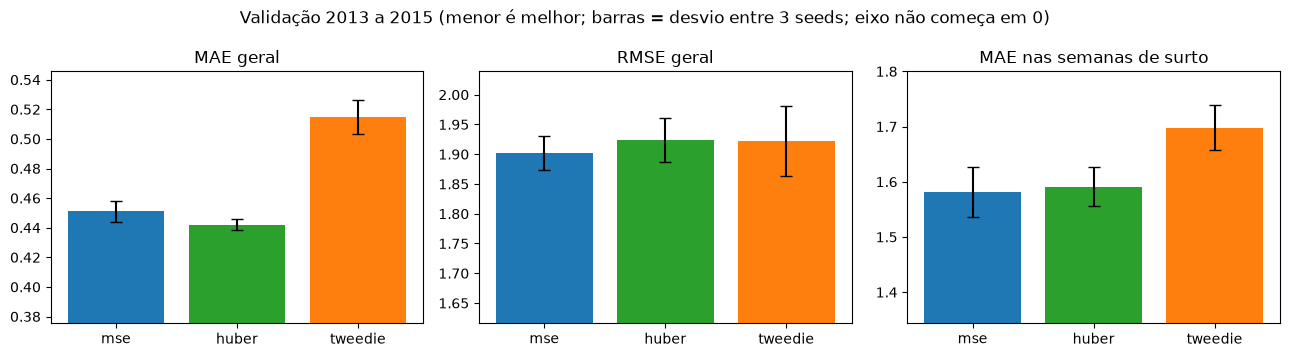

In [2]:
cores = {'mse': 'tab:blue', 'huber': 'tab:green', 'tweedie': 'tab:orange'}
perdas = list(tabela.index)
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
titulos = {'mae': 'MAE geral', 'rmse': 'RMSE geral', 'mae_surto': 'MAE nas semanas de surto'}
for ax, m in zip(eixos, titulos):
    ax.bar(perdas, tabela[m + '_media'], yerr=tabela[m + '_desvio'], capsize=4,
           color=[cores[p] for p in perdas])
    ax.set_title(titulos[m])
    ax.set_ylim(tabela[m + '_media'].min() * 0.85, tabela[m + '_media'].max() * 1.06)
fig.suptitle('Validação 2013 a 2015 (menor é melhor; barras = desvio entre 3 seeds; eixo não começa em 0)')
plt.tight_layout()
plt.show()

**Conclusão:** a Huber tem o menor MAE (0,442 ± 0,004 contra 0,451 ± 0,007 do MSE). O ganho é pequeno, cerca de 2%, e equivale a uns 2 desvios-padrão da média com 3 seeds: é provável, não garantido. No RMSE e no MAE de surto, MSE e Huber empatam dentro do desvio. A Tweedie é a pior no MAE (0,515), uns 14% acima do MSE, e empata no RMSE. As três superam o LSTM (0,472) e a persistência (0,609).

### Pergunta 2: a vantagem se mantém em todos os horizontes?

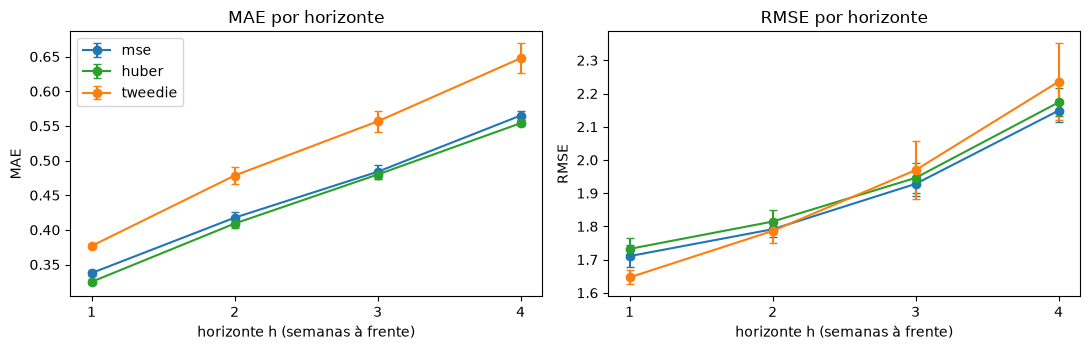

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for p in perdas:
    for ax, m in zip(eixos, ['mae', 'rmse']):
        ax.errorbar(H, tabela.loc[p, [f'{m}_h{h}_media' for h in H]],
                    yerr=tabela.loc[p, [f'{m}_h{h}_desvio' for h in H]],
                    marker='o', capsize=3, color=cores[p], label=p)
for ax, m in zip(eixos, ['MAE', 'RMSE']):
    ax.set(xlabel='horizonte h (semanas à frente)', ylabel=m, xticks=H, title=f'{m} por horizonte')
eixos[0].legend()
plt.tight_layout()
plt.show()

**Conclusão:** sim. A Huber fica um pouco abaixo do MSE no MAE em todos os horizontes (de 0,325 contra 0,338 em h = 1 a 0,554 contra 0,565 em h = 4), e a Tweedie fica acima das duas em todos. No RMSE as curvas se sobrepõem, como na pergunta 1. A ordem não muda com o horizonte, então a escolha da perda não depende de quão longe queremos prever.

### Pergunta 3: as perdas erram para o mesmo lado em surto e em calmaria?

O **viés** é a média de (previsto − real). Positivo quer dizer que o modelo superestima.

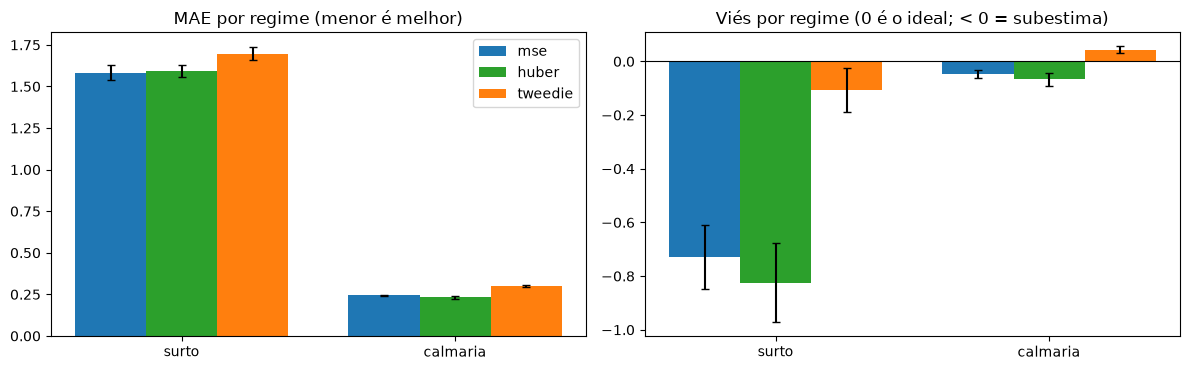

In [4]:
regimes = ['surto', 'calmaria']
x = np.arange(len(regimes))
largura = 0.26
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
for i, p in enumerate(perdas):
    for ax, m in zip(eixos, ['mae', 'vies']):
        ax.bar(x + (i - 1) * largura, [tabela.loc[p, f'{m}_{r}_media'] for r in regimes], largura,
               yerr=[tabela.loc[p, f'{m}_{r}_desvio'] for r in regimes], capsize=3,
               color=cores[p], label=p)
eixos[0].set(title='MAE por regime (menor é melhor)', xticks=x, xticklabels=regimes)
eixos[1].set(title='Viés por regime (0 é o ideal; < 0 = subestima)', xticks=x, xticklabels=regimes)
eixos[1].axhline(0, color='k', lw=0.8)
eixos[0].legend()
plt.tight_layout()
plt.show()

**Conclusão:** as perdas em `log1p` (MSE e Huber) **subestimam os surtos** com folga: o viés é de −0,73 (MSE) e −0,82 (Huber). Isso é esperado. Minimizar o erro em `log1p` faz o modelo estimar algo parecido com a média do *log*, e `expm1` disso fica abaixo da média da taxa (desigualdade de Jensen). Quanto maior a variância, maior a diferença, e ela é maior nos surtos. A Tweedie estima a média da própria taxa e quase zera o viés nos surtos (−0,11). O preço é que ela **superestima as semanas calmas** (viés +0,04) e erra mais nelas (MAE 0,299 contra 0,245 do MSE). Isso confirma o que o projeto antigo tinha visto. E zerar o viés não basta: mesmo assim, a Tweedie tem o pior MAE nos surtos (1,70). Ela acerta a média, mas erra mais em cada semana. Como 85% das semanas da validação são calmas, esse preço domina o MAE geral.

### Resumo e decisão

| Perda | MAE | RMSE | MAE surto | Viés surto | Viés calmaria |
| --- | --- | --- | --- | --- | --- |
| MSE | 0,451 ± 0,007 | 1,902 ± 0,028 | 1,582 ± 0,045 | −0,73 | −0,05 |
| **Huber** | **0,442 ± 0,004** | 1,924 ± 0,037 | 1,591 ± 0,035 | −0,82 | −0,07 |
| Tweedie | 0,515 ± 0,011 | 1,923 ± 0,058 | 1,698 ± 0,040 | −0,11 | +0,04 |

- A Tweedie fica fora: ela piora o MAE em 14% e superestima as semanas calmas, que são a maioria.
- Huber e MSE estão praticamente empatados. A Huber ganha um pouco no MAE, de forma consistente em todos os horizontes, e empata no RMSE e no surto. A perda da avaliação final (task 21) fica entre as duas, e a decisão é combinada com a task 19.
- Lição para o relatório: o MSE em `log1p` não é neutro. Ele puxa as previsões dos surtos para baixo. Quem usa a previsão para alertar sobre surtos precisa saber disso.